## THƯ VIỆN 


In [30]:
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

## KIỂM TRA THIẾT BỊ 

In [31]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


## LOAD DATA


In [32]:
import pandas as pd

train = pd.read_csv("../data/processed/train_processed.csv")
test = pd.read_csv("../data/processed/test_processed.csv")

## TÁCH FEATURE VÀ TARGET

In [33]:
X = train.drop(columns=["SalePrice"])
y = train["SalePrice"]
## Kiểm tra 
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1460, 317)
y shape: (1460,)


## TRAIN/VALIDATION SPIT

In [34]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
# Kiểm tra kích thước 
print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (1168, 317)
X_valid: (292, 317)
y_train: (1168,)
y_valid: (292,)


In [35]:
X_train = X_train.drop(columns=["split"])
X_valid = X_valid.drop(columns=["split"])

## Chuyển sang Pytorch Tensor 

In [36]:
X_train_tensor = torch.tensor(
    X_train.values,
    dtype=torch.float32
)

X_valid_tensor = torch.tensor(
    X_valid.values,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.values,
    dtype=torch.float32
)

y_valid_tensor = torch.tensor(
    y_valid.values,
    dtype=torch.float32
)
# Kiểm tra 
print("X_train_tensor:", X_train_tensor.shape)
print("y_train_tensor:", y_train_tensor.shape)

print("X dtype:", X_train_tensor.dtype)
print("y dtype:", y_train_tensor.dtype)

X_train_tensor: torch.Size([1168, 316])
y_train_tensor: torch.Size([1168])
X dtype: torch.float32
y dtype: torch.float32


## Định nghĩa Dataset 

In [37]:
class HousePriceDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = X.float()
        self.y = None

        if y is not None:
            self.y = y.float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.X[idx], self.y[idx]

        return self.X[idx]

## Định nghĩa mô hình MLP 

In [38]:
class MLPRegressor(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

## Tạo Dataset 

In [39]:
train_dataset = HousePriceDataset(
    X_train_tensor,
    y_train_tensor
)

valid_dataset = HousePriceDataset(
    X_valid_tensor,
    y_valid_tensor
)
# Kiểm tra 1 mẫu 
sample_X, sample_y = train_dataset[0]

print("Sample X shape:", sample_X.shape)
print("Sample y:", sample_y)

Sample X shape: torch.Size([316])
Sample y: tensor(145000.)


## Tạo Dataloader

In [40]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False
)
# kiểm tra 1 batch 
X_batch, y_batch = next(iter(train_loader))

print("Batch X shape:", X_batch.shape)
print("Batch y shape:", y_batch.shape)

Batch X shape: torch.Size([32, 316])
Batch y shape: torch.Size([32])


## Khởi tạo mô hình 

In [41]:
input_dim = X_train_tensor.shape[1]

model = MLPRegressor(
    input_dim=input_dim
).to(device)

print(model)

MLPRegressor(
  (network): Sequential(
    (0): Linear(in_features=316, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


## Khai báo loss và optimizer

In [42]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

## Training và Validation

In [43]:
train_losses = []
valid_losses = []

for epoch in range(epochs):

    # --------------------
    # Training
    # --------------------
    model.train()

    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch).squeeze(-1)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # --------------------
    # Validation
    # --------------------
    model.eval()

    valid_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in valid_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch).squeeze(-1)

            loss = criterion(predictions, y_batch)

            valid_loss += loss.item()

    valid_loss /= len(valid_loader)

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print(
        f"Epoch [{epoch + 1:03d}/{epochs}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Valid Loss: {valid_loss:.6f}"
    )

Epoch [001/100] | Train Loss: 38649088996.324326 | Valid Loss: 38926240358.400002
Epoch [002/100] | Train Loss: 38510525965.837837 | Valid Loss: 38090376601.599998
Epoch [003/100] | Train Loss: 36762894225.297295 | Valid Loss: 35165492019.199997
Epoch [004/100] | Train Loss: 32470444032.000000 | Valid Loss: 29190260326.400002
Epoch [005/100] | Train Loss: 25451631588.324326 | Valid Loss: 21377014784.000000
Epoch [006/100] | Train Loss: 18001215571.027027 | Valid Loss: 15394064204.799999
Epoch [007/100] | Train Loss: 14040667385.081081 | Valid Loss: 13416475712.000000
Epoch [008/100] | Train Loss: 13299225115.675676 | Valid Loss: 13147642604.799999
Epoch [009/100] | Train Loss: 13040708033.729731 | Valid Loss: 13033186572.799999
Epoch [010/100] | Train Loss: 13062120918.486486 | Valid Loss: 12925139097.600000
Epoch [011/100] | Train Loss: 12858674037.621622 | Valid Loss: 12811654179.200001
Epoch [012/100] | Train Loss: 12698326237.405405 | Valid Loss: 12696478067.200001
Epoch [013/100] 

## Loss Grapht

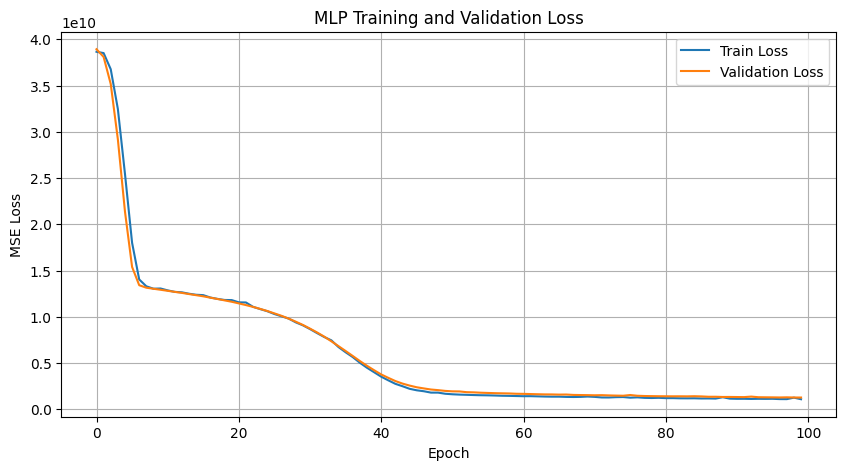

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(valid_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("MLP Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

## Save model 

In [45]:
import os

os.makedirs("../models", exist_ok=True)
model_path = "../models/mlp_model.pth"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": input_dim,
        "epochs": epochs,
        "batch_size": batch_size,
        "learning_rate": 0.001,
        "train_losses": train_losses,
        "valid_losses": valid_losses
    },
    model_path
)

print("Model saved to:", model_path)

Model saved to: ../models/mlp_model.pth


## Kiểm tra khả năng dự đoán 

In [46]:
model.eval()

with torch.no_grad():
    sample_input = X_valid_tensor[:5].to(device)
    sample_prediction = model(sample_input).squeeze(-1)

print("Predictions:")
print(sample_prediction.cpu())

print("\nActual values:")
print(y_valid_tensor[:5])

Predictions:
tensor([128913.5469, 308766.5000,  99398.9375, 161297.5625, 293363.0625])

Actual values:
tensor([154500., 325000., 115000., 159000., 315500.])
